# Hybrid ML + NLP model

This notebook uses the processed dataset for `combined_text` and the raw engineered numeric columns. The preprocessing stage saved categorical predictors as one-hot columns rather than raw category values. To use a fresh, train-only `OneHotEncoder` as requested, this notebook restores only the inspected metadata columns from `data/raw/DataSet.csv`, repeats the same exact-row deduplication, and verifies that row order aligns by rebuilding and comparing `combined_text` and the target. It does not use the already encoded columns.

A new stratified 80/20 train/test split is made. An inner stratified validation split within training chooses the model using PR-AUC (then fraud F1); test data is reserved for final metrics. A `ColumnTransformer` combines TF-IDF text, imputed/one-hot metadata, and imputed/scaled numeric indicators inside a scikit-learn `Pipeline`, so all learned preprocessing fits on training rows only. No SMOTE is used.

The fraud class is the positive label (`t` = 1). Accuracy alone is misleading because legitimate postings are the majority: a model could predict every posting as legitimate and still appear accurate while detecting no fraud. We therefore report fraud precision, recall, F1, ROC-AUC, PR-AUC, confusion matrices, and full classification reports. Scores are estimates on this dataset, not guarantees that the model is perfect.

Processed rows verified against raw CSV: 17,645
Categorical predictors: ['location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'telecommuting', 'has_company_logo', 'has_questions']
Numeric scam-indicator predictors: 16
Class counts:


,count
fraudulent,
legitimate (f),16787
fraudulent (t),858


Outer training=14,116; held-out test=3,529; inner fit=11,292; validation=2,824
XGBoost scale_pos_weight = 13430 / 686 = 19.5773

Fit validation candidate: Logistic Regression (balanced)



Fit validation candidate: Linear SVM (balanced)



Fit validation candidate: Random Forest (balanced)



Fit validation candidate: XGBoost (weighted)


... (4 outputs left out)

                precision    recall  f1-score   support

Legitimate (f)     0.9911    0.9899    0.9905      3357
Fraudulent (t)     0.8068    0.8256    0.8161       172

      accuracy                         0.9819      3529
     macro avg     0.8989    0.9077    0.9033      3529
  weighted avg     0.9821    0.9819    0.9820      3529


Fit full training pipeline: Random Forest (balanced)


                precision    recall  f1-score   support

Legitimate (f)     0.9864    0.9961    0.9913      3357
Fraudulent (t)     0.9065    0.7326    0.8103       172

      accuracy                         0.9833      3529
     macro avg     0.9465    0.8643    0.9008      3529
  weighted avg     0.9825    0.9833    0.9824      3529


Fit full training pipeline: XGBoost (weighted)


                precision    recall  f1-score   support

Legitimate (f)     0.9923    0.9923    0.9923      3357
Fraudulent (t)     0.8488    0.8488    0.8488       172

      accuracy                         0.9853      3529
     macro avg     0.9205    0.9205    0.9205      3529
  weighted avg     0.9853    0.9853    0.9853      3529


Held-out test comparison (selection used the separate training-validation split):


,model_name,features_used,accuracy,fraud_precision,fraud_recall,fraud_f1_score,roc_auc,pr_auc,validation_pr_auc,validation_f1_fraud
0,XGBoost (weighted),TF-IDF text + one-hot metadata + scaled scam indicators,0.9853,0.8488,0.8488,0.8488,0.9914,0.9131,0.9217,0.8240
1,Linear SVM (balanced),TF-IDF text + one-hot metadata + scaled scam indicators,0.9819,0.8068,0.8256,0.8161,0.9856,0.8958,0.9273,0.8487
2,Random Forest (balanced),TF-IDF text + one-hot metadata + scaled scam indicators,0.9833,0.9065,0.7326,0.8103,0.9909,0.8984,0.9140,0.8049
3,Logistic Regression (balanced),TF-IDF text + one-hot metadata + scaled scam indicators,0.9680,0.6166,0.9070,0.7341,0.9864,0.8266,0.8669,0.7251


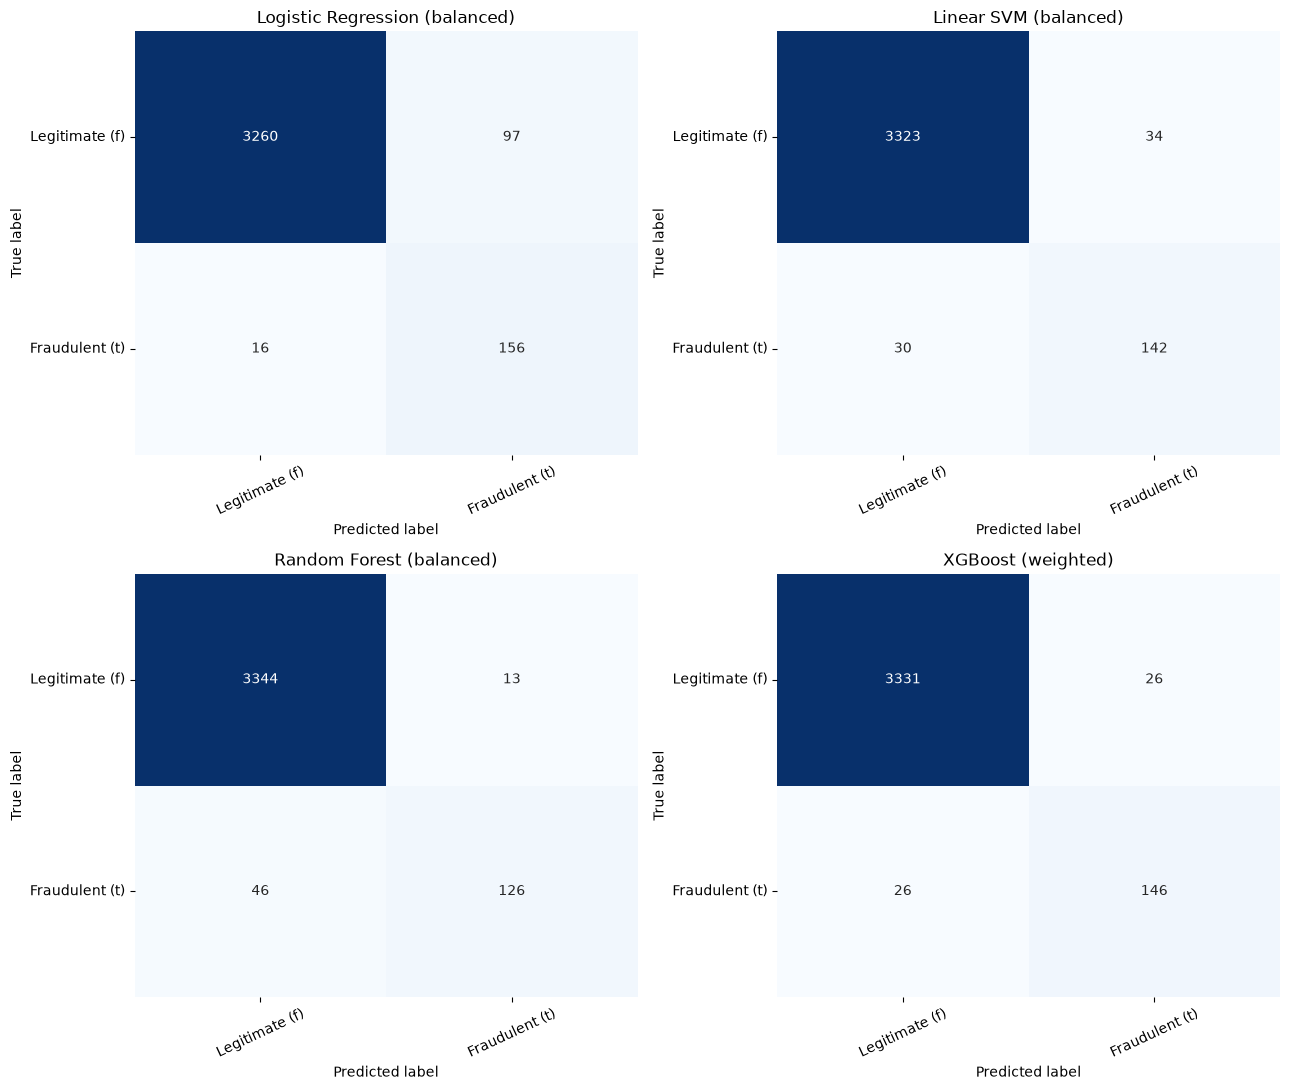


Selected on training validation: Linear SVM (balanced)
Validation PR-AUC: 0.9273; validation fraud F1: 0.8487
Held-out test fraud F1: 0.8161; test PR-AUC: 0.8958
Saved complete hybrid pipeline: models\best_hybrid_model.joblib
Saved experiment table: report\hybrid_model_experiments.csv
Saved classification reports: report\hybrid_classification_reports.txt
Saved confusion matrix plot: report\hybrid_confusion_matrices.png
Joblib reload and sample-prediction check passed.


In [1]:
from pathlib import Path
import json
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from IPython.display import display

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif PROJECT_DIR.name != "fake-job-detector" and (PROJECT_DIR / "fake-job-detector").is_dir():
    PROJECT_DIR = PROJECT_DIR / "fake-job-detector"

PROCESSED_PATH = PROJECT_DIR / "data" / "processed" / "processed_job_postings.csv"
RAW_PATH = PROJECT_DIR / "data" / "raw" / "DataSet.csv"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "report"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
for path in (PROCESSED_PATH, RAW_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset file was not found: {path}")

numeric_features = [
    "raw__description_length", "raw__requirements_length", "raw__word_count",
    "raw__character_count", "raw__url_count", "raw__email_count",
    "raw__phone_count", "raw__exclamation_count", "raw__missing_company_profile",
    "raw__contains_urgent_language", "raw__contains_fee_request", "raw__contains_easy_money",
    "raw__contains_no_experience", "raw__contains_work_from_home",
    "raw__contains_cryptocurrency_payment", "raw__contains_whatsapp_or_telegram",
]
categorical_candidates = [
    "location", "department", "salary_range", "employment_type",
    "required_experience", "required_education", "industry", "function",
    "telecommuting", "has_company_logo", "has_questions",
]

# Load model inputs from the processed CSV; ignore split and prior one-hot/scaled columns.
processed = pd.read_csv(
    PROCESSED_PATH,
    usecols=["combined_text", "fraudulent", *numeric_features],
    low_memory=False,
)
raw_columns = pd.read_csv(RAW_PATH, nrows=0).columns.tolist()
categorical_features = [column for column in categorical_candidates if column in raw_columns]
if not categorical_features:
    raise ValueError("No inspected categorical metadata columns are present in the raw dataset.")
# Read all source columns before deduplication: otherwise rows differing only in an
# omitted field can be incorrectly collapsed and break alignment with processed rows.
raw = pd.read_csv(RAW_PATH, low_memory=False)

# Reproduce stage 2's order of operations: exact duplicates were removed before blank normalization.
raw = raw.drop_duplicates().copy()
raw = raw[[*categorical_features, "fraudulent", "title", "company_profile", "description", "requirements", "benefits"]].copy()
if len(raw) != len(processed):
    raise ValueError(f"Cannot align raw metadata to processed rows: raw deduplicated={len(raw)}, processed={len(processed)}")
for column in raw.select_dtypes(include=["object", "string"]).columns:
    raw[column] = raw[column].replace(r"^\s*$", pd.NA, regex=True)

text_columns = [column for column in ["title", "company_profile", "description", "requirements", "benefits"] if column in raw]
def clean_text(value):
    text = "" if pd.isna(value) else str(value)
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\b(?:https?://|www\.)\S+", " URL ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[\w.+%-]+@[\w.-]+\.[a-z]{2,}\b", " EMAIL ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

raw_text = raw[text_columns].fillna("").astype(str).agg(" ".join, axis=1).map(clean_text)
processed_text = processed["combined_text"].fillna("").astype(str)
if not np.array_equal(raw_text.to_numpy(), processed_text.to_numpy()):
    mismatch = np.flatnonzero(raw_text.to_numpy() != processed_text.to_numpy())[:5].tolist()
    raise ValueError(f"Raw metadata rows do not align with processed text; first mismatches: {mismatch}")
raw_labels = raw["fraudulent"].astype(str).str.strip().str.lower().reset_index(drop=True)
processed_labels = processed["fraudulent"].astype(str).str.strip().str.lower()
if not np.array_equal(raw_labels.to_numpy(), processed_labels.to_numpy()):
    raise ValueError("Raw and processed fraud labels are not aligned row by row.")

data = processed.copy()
for column in categorical_features:
    data[column] = raw[column].reset_index(drop=True)
data["combined_text"] = processed_text
data["fraudulent"] = processed_labels
label_map = {"f": 0, "t": 1}
unexpected = sorted(set(data["fraudulent"].unique()) - set(label_map))
if unexpected:
    raise ValueError(f"Unexpected fraud labels: {unexpected}")
X = data[["combined_text", *categorical_features, *numeric_features]].copy()
y = data["fraudulent"].map(label_map).astype("int8")
print(f"Processed rows verified against raw CSV: {len(data):,}")
print("Categorical predictors:", categorical_features)
print(f"Numeric scam-indicator predictors: {len(numeric_features)}")
print("Class counts:")
display(y.value_counts().sort_index().rename(index={0: "legitimate (f)", 1: "fraudulent (t)"}).rename("count").to_frame())

# Outer stratified test split. Learned transforms are not fitted until below, on training rows.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
# Select the winning model on training-only validation; final test rows do not select it.
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)
print(f"Outer training={len(X_train):,}; held-out test={len(X_test):,}; inner fit={len(X_fit):,}; validation={len(X_validation):,}")
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count
print(f"XGBoost scale_pos_weight = {negative_count} / {positive_count} = {scale_pos_weight:.4f}")

def make_preprocessor():
    """Construct fresh train-fitted text, categorical, and numeric transforms."""
    text_vectorizer = TfidfVectorizer(
        max_features=10_000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
    )
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, dtype=np.float32)),
    ])
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        # Keep sparse combined matrices sparse; StandardScaler still learns on train rows only.
        ("scaler", StandardScaler(with_mean=False)),
    ])
    return ColumnTransformer(
        transformers=[
            ("text", text_vectorizer, "combined_text"),
            ("categorical", categorical_pipeline, categorical_features),
            ("numeric", numeric_pipeline, numeric_features),
        ],
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=True,
    )

def make_pipeline(classifier):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier),
    ])

def make_models():
    return {
        "Logistic Regression (balanced)": make_pipeline(
            LogisticRegression(class_weight="balanced", max_iter=1500, random_state=42)
        ),
        "Linear SVM (balanced)": make_pipeline(
            LinearSVC(class_weight="balanced", random_state=42)
        ),
        "Random Forest (balanced)": make_pipeline(
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
                min_samples_leaf=2,
            )
        ),
        "XGBoost (weighted)": make_pipeline(
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="aucpr",
                scale_pos_weight=scale_pos_weight,
                n_estimators=250,
                max_depth=5,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                reg_lambda=1.0,
                tree_method="hist",
                n_jobs=-1,
                random_state=42,
            )
        ),
    }

def fraud_scores(pipeline, frame):
    if hasattr(pipeline, "predict_proba"):
        return pipeline.predict_proba(frame)[:, 1]
    if hasattr(pipeline, "decision_function"):
        return pipeline.decision_function(frame)
    return None

# First fit candidate pipelines on the inner training subset. Validation selects the winner.
validation_results = []
for model_name, candidate in make_models().items():
    print(f"\nFit validation candidate: {model_name}")
    candidate.fit(X_fit, y_fit)
    scores = fraud_scores(candidate, X_validation)
    predicted = candidate.predict(X_validation)
    validation_results.append({
        "model": model_name,
        "validation_pr_auc": average_precision_score(y_validation, scores),
        "validation_f1_fraud": f1_score(y_validation, predicted, pos_label=1, zero_division=0),
    })
validation_table = pd.DataFrame(validation_results).sort_values(
    ["validation_pr_auc", "validation_f1_fraud"], ascending=False
    ).reset_index(drop=True)
print("\nTraining-only validation ranking:")
display(validation_table)
best_model_name = str(validation_table.loc[0, "model"])

# Refit every model using the full outer training partition for comparable held-out test metrics.
test_results = []
classification_reports = {}
confusion_matrices = {}
full_training_models = {}
class_order = [0, 1]
target_names = ["Legitimate (f)", "Fraudulent (t)"]
for model_name, pipeline in make_models().items():
    print(f"\nFit full training pipeline: {model_name}")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    scores = fraud_scores(pipeline, X_test)
    test_results.append({
        "model_name": model_name,
        "features_used": "TF-IDF text + one-hot metadata + scaled scam indicators",
        "accuracy": accuracy_score(y_test, predictions),
        "fraud_precision": precision_score(y_test, predictions, pos_label=1, zero_division=0),
        "fraud_recall": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "fraud_f1_score": f1_score(y_test, predictions, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_test, scores),
        "pr_auc": average_precision_score(y_test, scores),
    })
    classification_reports[model_name] = classification_report(
        y_test, predictions, labels=class_order, target_names=target_names,
        digits=4, zero_division=0,
    )
    confusion_matrices[model_name] = confusion_matrix(y_test, predictions, labels=class_order)
    full_training_models[model_name] = pipeline
    print(classification_reports[model_name])

experiment_table = pd.DataFrame(test_results)
experiment_table = experiment_table.merge(validation_table, left_on="model_name", right_on="model", how="left").drop(columns="model")
experiment_table = experiment_table.sort_values(
    ["fraud_f1_score", "pr_auc"], ascending=False
    ).reset_index(drop=True)
print("\nHeld-out test comparison (selection used the separate training-validation split):")
display(experiment_table.style.format({
    "accuracy": "{:.4f}", "fraud_precision": "{:.4f}", "fraud_recall": "{:.4f}",
    "fraud_f1_score": "{:.4f}", "roc_auc": "{:.4f}", "pr_auc": "{:.4f}",
    "validation_pr_auc": "{:.4f}", "validation_f1_fraud": "{:.4f}",
}))

# Confusion matrices use true labels on rows and predicted labels on columns.
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (model_name, matrix) in zip(axes.flat, confusion_matrices.items()):
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=target_names, yticklabels=target_names, ax=ax,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
confusion_plot_path = REPORT_DIR / "hybrid_confusion_matrices.png"
fig.savefig(confusion_plot_path, dpi=150, bbox_inches="tight")
plt.show()

# Selection was made using validation PR-AUC, not the held-out test results.
best_pipeline = full_training_models[best_model_name]
model_path = MODEL_DIR / "best_hybrid_model.joblib"
joblib.dump(best_pipeline, model_path)
experiment_path = REPORT_DIR / "hybrid_model_experiments.csv"
experiment_table.to_csv(experiment_path, index=False)
classification_path = REPORT_DIR / "hybrid_classification_reports.txt"
classification_path.write_text(
    "\n\n".join(f"{name}\n{'=' * len(name)}\n{report}" for name, report in classification_reports.items()),
    encoding="utf-8",
)
metadata_path = MODEL_DIR / "best_hybrid_model_metadata.json"
best_test_row = experiment_table.loc[experiment_table["model_name"].eq(best_model_name)].iloc[0]
metadata_path.write_text(json.dumps({
    "selected_model": best_model_name,
    "selection_metric": "training-validation PR-AUC (average precision), fraud F1 as tie-breaker",
    "positive_label": "t",
    "label_mapping": {"f": 0, "t": 1},
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "tfidf": {"max_features": 10000, "ngram_range": [1, 2], "min_df": 2, "sublinear_tf": True},
    "xgboost_scale_pos_weight": scale_pos_weight,
    "selected_model_test_metrics": best_test_row.to_dict(),
}, indent=2, default=float), encoding="utf-8")

best_validation_row = validation_table.loc[validation_table["model"].eq(best_model_name)].iloc[0]
print(f"\nSelected on training validation: {best_model_name}")
print(f"Validation PR-AUC: {best_validation_row['validation_pr_auc']:.4f}; validation fraud F1: {best_validation_row['validation_f1_fraud']:.4f}")
print(f"Held-out test fraud F1: {best_test_row['fraud_f1_score']:.4f}; test PR-AUC: {best_test_row['pr_auc']:.4f}")
print(f"Saved complete hybrid pipeline: {model_path.relative_to(PROJECT_DIR)}")
print(f"Saved experiment table: {experiment_path.relative_to(PROJECT_DIR)}")
print(f"Saved classification reports: {classification_path.relative_to(PROJECT_DIR)}")
print(f"Saved confusion matrix plot: {confusion_plot_path.relative_to(PROJECT_DIR)}")

# Confirm serialization preserves a working preprocessing + model pipeline.
reloaded = joblib.load(model_path)
assert len(reloaded.predict(X_test.iloc[:5])) == min(5, len(X_test))
print("Joblib reload and sample-prediction check passed.")


## How to interpret the comparison

The table reports held-out test scores for all four hybrid models. The saved model is selected using the separate validation split from the training partition, not by picking the highest test score. In an imbalanced task, precision tells how many flagged postings are truly fraud, recall tells how many fraud postings were found, and F1 balances the two. PR-AUC summarizes precision/recall over thresholds; ROC-AUC measures ranking over both classes. None alone makes a detector perfect or establishes that a posting is definitively fraudulent.

Check the actual experiment table for the best result: if the selected pipeline also leads on held-out fraud F1 or PR-AUC, that supports its performance in this experiment; if rankings differ, describe the trade-off rather than claiming a universal winner. Any further model tuning should use training-only validation, not repeatedly optimize against the held-out test set.